# Fit a ramp and build an image

This guide fits a preprocessed ramp to get the flux of each pixel, checks the
result, and turns it into a 2D `~mercupix.image.Exposure`.

We use a small simulated ramp so that this page runs anywhere. The
`make_toy_ramp` helper is described in {doc}`howto_load_ramp`; with real data,
skip this cell and load your own file.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 90

import numpy as np
from astropy.io import fits

def make_toy_ramp(filename, ngroups=30, dt=2.8, size=128, nrefpixels=4, nchannels=4,
                  readnoise=10., bias=10_000., n_cosmics=30, seed=0):
    """Simulate a raw HxRG ramp in pyxim format and return the truth.

    The active area sees a flat background, a few stars (one of them
    saturating) and cosmic rays. All pixels, reference pixels included,
    share a per-channel and per-row offset that drifts from group to group.
    """
    rng = np.random.default_rng(seed)
    n = size + 2 * nrefpixels
    act = slice(nrefpixels, -nrefpixels)
    times = np.arange(1, ngroups + 1, dtype="float32") * dt

    # True flux [ADU/s] on the active area: background + stars.
    yy, xx = np.mgrid[:size, :size]
    flux = np.full((size, size), 5.)
    for y0, x0, amp in [(40, 40, 300.), (90, 30, 80.), (64, 100, 3_000.), (100, 90, 20.)]:
        flux += amp * np.exp(-((yy - y0)**2 + (xx - x0)**2) / (2 * 2.**2))

    # Accumulated photo-electrons (gain = 1) with Poisson noise.
    signal = np.zeros((ngroups, n, n))
    signal[:, act, act] = np.cumsum(rng.poisson(flux[None] * dt, (ngroups, size, size)), axis=0)

    # Cosmic rays: a jump that stays in the ramp from a random group onwards.
    cosmics = []
    for _ in range(n_cosmics):
        y, x, g = rng.integers(0, size), rng.integers(0, size), rng.integers(1, ngroups)
        amp = rng.uniform(300, 3_000)
        signal[g:, y + nrefpixels, x + nrefpixels] += amp
        cosmics.append((y, x, g, amp))

    # Correlated read noise seen by the reference pixels too.
    npix_channel = n // nchannels
    channel_offset = np.repeat(rng.normal(0, 30, (ngroups, nchannels)), npix_channel, axis=1)
    row_offset = rng.normal(0, 5, (ngroups, n))
    raw = (bias + signal + channel_offset[:, None, :] + row_offset[:, :, None]
           + rng.normal(0, readnoise, signal.shape))
    raw = np.clip(raw, 0, 65_535).astype("uint16")

    primary = fits.PrimaryHDU(raw)
    primary.header["NCHAN"] = nchannels
    table = fits.BinTableHDU.from_columns([fits.Column("readout_times", "E", array=times)])
    fits.HDUList([primary, table]).writeto(filename, overwrite=True)
    return dict(flux=flux, cosmics=cosmics, times=times, readnoise=readnoise)

truth = make_toy_ramp("toy_ramp.fits")

In [2]:
from mercupix.ramp import RawRamp

ramp = RawRamp.from_filename("toy_ramp.fits", datatype="pyxim")

## One call: `fit_ramp`

`~mercupix.fitter.fit_ramp` preprocesses the ramp with `raw_ramp_kwargs` (see
{doc}`howto_preprocess`), then fits it with the method named by `method`.
Arguments of the fitter go in `**kwargs`, arguments of its `fit` method in
`fit_args`.

Here we use `~mercupix.fitter.Brandt2024`, which detects and drops the cosmic
rays during the fit. Saturated groups are masked so they are ignored.

In [3]:
from mercupix.fitter import fit_ramp

result = fit_ramp(
    ramp,
    method="Brandt",
    raw_ramp_kwargs=dict(corr_refpix=True, mask=True,
                         mask_kwargs=dict(disconnected=False, saturated=True)),
    fit_args=dict(jumps=True, jump_threshold=[20, 30]),
    readnoise=truth["readnoise"],
)
result

## The fit result

All fitters return a `~mercupix.fitter.RampFitResults`:

| attribute | content |
|---|---|
| `slope` | flux: slope of the fitted ramp at `t = 0`, in ADU per unit of `times` (here ADU/s) |
| `var` | variance of the slope |
| `qof` | quality of fit (chi-square) |
| `offset` | value of the fitted ramp at `t = 0`, when the fitter provides it |
| `mask2d`, `mask3d` | data quality information from the fit |

For `Brandt2024`, `mask2d` counts the group differences kept after the jump
detection.

slope : (128, 128)
pixels with dropped differences: 70


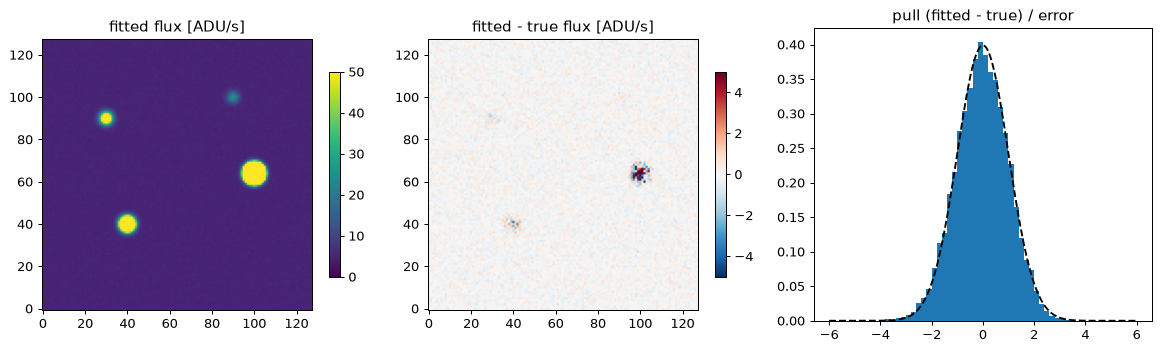

In [4]:
ndiff = ramp.ngroups - 1
print("slope :", result.slope.shape)
print("pixels with dropped differences:", int((result.mask2d < ndiff).sum()))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
im = axes[0].imshow(result.slope, origin="lower", vmin=0, vmax=50)
fig.colorbar(im, ax=axes[0], shrink=0.7)
axes[0].set_title("fitted flux [ADU/s]")

im = axes[1].imshow(result.slope - truth["flux"], origin="lower", vmin=-5, vmax=5, cmap="RdBu_r")
fig.colorbar(im, ax=axes[1], shrink=0.7)
axes[1].set_title("fitted - true flux [ADU/s]")

pull = (result.slope - truth["flux"]) / np.sqrt(result.var)
axes[2].hist(pull[result.mask2d == ndiff].ravel(), bins=60, range=(-6, 6), density=True)
xx = np.linspace(-6, 6, 200)
axes[2].plot(xx, np.exp(-xx**2 / 2) / np.sqrt(2 * np.pi), "k--")
axes[2].set_title("pull (fitted - true) / error")
fig.tight_layout()
plt.show()

The background is recovered without bias. The pulls follow a unit normal,
so the variance is consistent with the scatter. The bright saturated star in
the middle of the map stays poorly constrained.

## Polynomial fit and residuals

To check the shape of the ramps, use a fitter directly. Here
`~mercupix.fitter.LSQFit` fits a degree-2 Legendre polynomial; with
`inplace=True` the coefficients are stored and
`~mercupix.fitter.Fitter.get_residuals` returns data minus model.

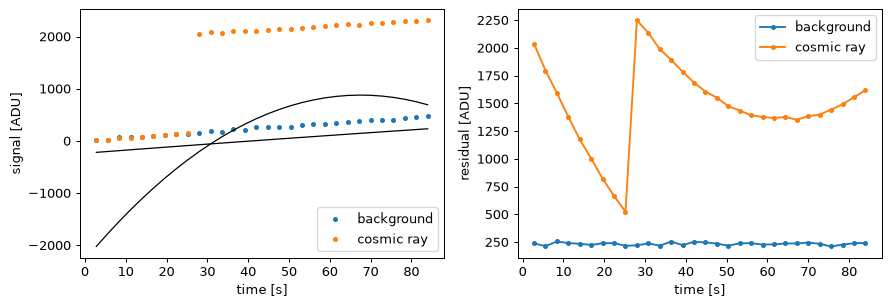

In [5]:
from mercupix.fitter import LSQFit

fitter = LSQFit.from_rawramp(ramp, ramp_kwargs=dict(corr_refpix=True), degree=2)
lsq = fitter.fit(inplace=True)
residuals = fitter.get_residuals()

y, x, g, amp = next(c for c in truth["cosmics"] if 8 <= c[2] <= 20)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for (py, px), label in [((10, 10), "background"), ((y, x), "cosmic ray")]:
    axes[0].plot(ramp.times, fitter.data[:, py, px], ".", label=label)
    axes[0].plot(ramp.times, fitter.get_model(pixels=(py, px)), "k-", lw=1)
    axes[1].plot(ramp.times, residuals[:, py, px], ".-", label=label)
axes[0].set_ylabel("signal [ADU]")
axes[1].set_ylabel("residual [ADU]")
for ax in axes:
    ax.set_xlabel("time [s]")
    ax.legend()
fig.tight_layout()
plt.show()

Without jump handling, the polynomial absorbs the cosmic ray and leaves
structured residuals. {doc}`compare_ramp_fitters` quantifies the impact.

## Build the 2D image

`~mercupix.image.Exposure` holds the final image, its mask and its variance,
and displays it with `~mercupix.image.Exposure.show`.

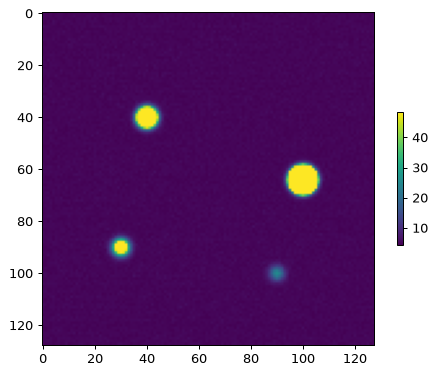

In [6]:
from mercupix.image import Exposure

exposure = Exposure(data=result.slope, mask=result.mask2d)
fig = exposure.show()